In [1]:
import cot_reports as cot
import pandas as pd

In [2]:
raw_data = cot.cot_all(cot_report_type = 'disaggregated_fut') 

Selected: COT Disaggregated report. Futures only.
Stored the extracted file F_Disagg06_16.txt in the working directory.
Selected: disaggregated_fut
Downloaded single year data from: 2017
Stored the file f_year.txt in the working directory.
Selected: disaggregated_fut
Downloaded single year data from: 2018
Stored the file f_year.txt in the working directory.
Selected: disaggregated_fut
Downloaded single year data from: 2019
Stored the file f_year.txt in the working directory.
Selected: disaggregated_fut
Downloaded single year data from: 2020
Stored the file f_year.txt in the working directory.
Selected: disaggregated_fut
Downloaded single year data from: 2021
Stored the file f_year.txt in the working directory.
Selected: disaggregated_fut
Downloaded single year data from: 2022
Stored the file f_year.txt in the working directory.
Selected: disaggregated_fut
Downloaded single year data from: 2023
Stored the file f_year.txt in the working directory.
Selected: disaggregated_fut
Downloaded s

In [3]:
names = raw_data['Market_and_Exchange_Names'].unique()
print([n for n in names if 'COFFEE' in n.upper()])

['COFFEE C - ICE FUTURES U.S.', 'COFFEE C - NEW YORK BOARD OF TRADE']


In [4]:
coffee = raw_data[raw_data['Market_and_Exchange_Names'].isin([
    'COFFEE C - ICE FUTURES U.S.',
    'COFFEE C - NEW YORK BOARD OF TRADE',
])]
print(coffee.shape)
                                                              

(1066, 191)


In [5]:
coffee = coffee[['Report_Date_as_YYYY-MM-DD', 'Open_Interest_All',
                 'M_Money_Positions_Long_All', 'M_Money_Positions_Short_All']]

coffee = coffee.rename(columns={
    'Report_Date_as_YYYY-MM-DD': 'date',
    'Open_Interest_All': 'oi',
    'M_Money_Positions_Long_All': 'mm_long',
    'M_Money_Positions_Short_All': 'mm_short',
})


coffee['date'] = pd.to_datetime(coffee['date'])
coffee = coffee.sort_values('date').set_index('date')

In [6]:
print(coffee.columns.tolist())
print(coffee.head())

['oi', 'mm_long', 'mm_short']
                oi  mm_long  mm_short
date                                 
2006-06-13  126941    12362     35265
2006-06-20  121700    12397     36042
2006-06-27  117763    12674     38431
2006-07-03  115862    12535     30882
2006-07-11  118855    13841     30558


In [7]:
coffee['net'] = coffee['mm_long'] - coffee['mm_short']
coffee['%_of_oi'] = (coffee['net'] / coffee['oi']) * 100

In [8]:
coffee['z-score'] = (coffee['%_of_oi'] - coffee['%_of_oi'].rolling(156).mean()) / coffee['%_of_oi'].rolling(156).std()

In [9]:
coffee['z-score'].describe()

count    911.000000
mean       0.071619
std        1.214064
min       -2.924635
25%       -0.881049
50%        0.105555
75%        1.114878
max        2.653757
Name: z-score, dtype: float64

In [10]:
coffee.tail()

,oi,mm_long,mm_short,net,%_of_oi,z-score
date,,,,,,
2026-10-13,163626,35096,19826,15270,9.332258,-1.847414
2026-10-20,170911,38596,16259,22337,13.069375,-1.339203
2026-10-27,171689,37556,17452,20104,11.709545,-1.555473
2026-11-03,166984,34613,19881,14732,8.822402,-1.981069
2026-11-10,154019,32213,21281,10932,7.097826,-2.205250


In [11]:
import yfinance as yf
import datetime as dt
import numpy as np

In [12]:
ticker = 'KC=F'
start = dt.datetime(2006, 6, 13)
end = dt.datetime.now()
df = yf.download(ticker, start=start, end=end)
weekly = df['Close'].squeeze().resample('W-MON').last()
weekly = weekly[weekly.index <= pd.Timestamp.today()]

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


In [13]:
future_rv_4w = (weekly.shift(-4) / weekly) - 1
future_rv_12w = (weekly.shift(-12) / weekly) - 1

In [14]:
days_to_monday = 7 - coffee.index.weekday
coffee['entry'] = coffee.index + pd.to_timedelta(days_to_monday, unit='D')

In [15]:
coffee['future_rv_4w'] = coffee['entry'].map(future_rv_4w)
coffee['future_rv_12w'] = coffee['entry'].map(future_rv_12w)

In [16]:
print(coffee['entry'].dt.day_name().value_counts())   # should be all Monday
print(coffee[['z-score', 'future_rv_4w', 'future_rv_12w']].tail(15))
print(coffee[['future_rv_4w', 'future_rv_12w']].describe())

entry
Monday    1066
Name: count, dtype: int64
             z-score  future_rv_4w  future_rv_12w
date                                             
2026-08-04 -0.158581     -0.024225      -0.120975
2026-08-11 -0.180818     -0.109389      -0.207186
2026-08-18 -0.144048     -0.268299      -0.256916
2026-08-25 -0.161156     -0.160366            NaN
2026-09-01 -0.435478     -0.097764            NaN
2026-09-08 -0.781430     -0.054498            NaN
2026-09-15 -0.918901      0.142185            NaN
2026-09-22 -1.390524      0.042251            NaN
2026-09-29 -1.468776     -0.001538            NaN
2026-10-06 -1.420991     -0.058500            NaN
2026-10-13 -1.847414     -0.110865            NaN
2026-10-20 -1.339203           NaN            NaN
2026-10-27 -1.555473           NaN            NaN
2026-11-03 -1.981069           NaN            NaN
2026-11-10 -2.205250           NaN            NaN
       future_rv_4w  future_rv_12w
count   1062.000000    1054.000000
mean       0.008365       0.02321

In [17]:
bins = [-np.inf, -1.5, -0.5, 0.5, 1.5, np.inf]
labels = ['Very short', 'Short', 'Neutral', 'Long', 'Very long']

coffee['pos_bucket'] = pd.cut(coffee['z-score'], bins=bins, labels=labels)

In [18]:
summary = coffee.groupby('pos_bucket', observed=True).agg(
    weeks=('future_rv_4w', 'count'),
        mean_4w=('future_rv_4w', 'mean'),
        win_4w=('future_rv_4w', lambda x: (x.dropna() > 0).mean() * 100),
        mean_12w=('future_rv_12w', 'mean'),
        win_12w=('future_rv_12w', lambda x: (x.dropna() > 0).mean() * 100),
)
print(summary)

            weeks   mean_4w     win_4w  mean_12w    win_12w
pos_bucket                                                 
Very short    101  0.009902  44.554455  0.022329  49.000000
Short         217 -0.001195  42.857143 -0.003319  35.849057
Neutral       191  0.007585  45.026178  0.030066  49.735450
Long          310  0.024640  58.064516  0.049439  58.064516
Very long      88 -0.026788  30.681818 -0.017483  43.181818


In [19]:
vl = coffee[coffee['pos_bucket'] == 'Very long'].copy()

gap = vl.index.to_series().diff() > pd.Timedelta(days=14)
vl['episode'] = gap.cumsum()

episodes = vl.groupby('episode').agg(
    start=('future_rv_4w', lambda x: x.index.min()),
    end=('future_rv_4w', lambda x: x.index.max()),
    weeks=('future_rv_4w', 'count'),
    mean_4w=('future_rv_4w', 'mean'),
)
print(episodes)
print(len(episodes), 'separate episodes')

             start        end  weeks   mean_4w
episode                                       
0       2009-10-20 2009-11-09      4  0.027066
1       2011-04-19 2011-05-03      3 -0.104892
2       2014-02-25 2014-10-28     36  0.002494
3       2014-11-18 2014-11-25      2 -0.110040
4       2019-12-03 2020-01-28      9 -0.075647
5       2020-03-10 2020-05-19     10 -0.058099
6       2020-08-04 2020-10-13     11 -0.030065
7       2021-02-23 2021-03-02      2 -0.056894
8       2021-11-23 2021-11-30      2 -0.068296
9       2024-04-09 2024-04-30      4 -0.041930
10      2024-06-18 2024-07-09      3  0.008008
11      2025-02-18 2025-02-25      2 -0.016996
12 separate episodes


In [20]:
from scipy.stats import spearmanr

d = coffee[['z-score', 'future_rv_4w']].dropna()
rho, p = spearmanr(d['z-score'], d['future_rv_4w'])

print(f'Spearman rho: {rho:.3f}, p-value: {p:.3f}')

Spearman rho: 0.021, p-value: 0.525


In [21]:
import statsmodels.api as sm

import statsmodels.api as sm

d = coffee[['future_rv_4w', 'pos_bucket']].dropna().copy()
d['very_long'] = (d['pos_bucket'] == 'Very long').astype(int)

X = sm.add_constant(d['very_long'])
model = sm.OLS(d['future_rv_4w'], X).fit(cov_type='HAC', cov_kwds={'maxlags': 8})
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           future_rv_4w   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.013
Method:                 Least Squares   F-statistic:                     7.039
Date:                Tue, 17 Nov 2026   Prob (F-statistic):            0.00811
Time:                        10:50:44   Log-Likelihood:                 838.68
No. Observations:                 907   AIC:                            -1673.
Df Residuals:                     905   BIC:                            -1664.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0120      0.006      2.046      0.0

In [22]:
def bucket_summary(data):
    return data.groupby('pos_bucket', observed=True).agg(
        weeks=('future_rv_4w', 'count'),
        mean_4w=('future_rv_4w', 'mean'),
        win_4w=('future_rv_4w', lambda x: (x.dropna() > 0).mean() * 100),
        mean_12w=('future_rv_12w', 'mean'),
    )

first = coffee[coffee.index < '2016-07-01']
second = coffee[coffee.index >= '2016-07-01']

print('2009–2016'); print(bucket_summary(first))
print('2016–2026'); print(bucket_summary(second))

2009–2016
            weeks   mean_4w     win_4w  mean_12w
pos_bucket                                      
Very short     41 -0.008309  36.585366 -0.046125
Short         114 -0.005110  45.614035  0.000237
Neutral        80  0.023163  50.000000  0.079013
Long           90  0.018069  55.555556  0.042830
Very long      45 -0.007483  42.222222 -0.036933
2016–2026
            weeks   mean_4w     win_4w  mean_12w
pos_bucket                                      
Very short     60  0.022346  50.000000  0.069898
Short         103  0.003138  39.805825 -0.007455
Neutral       111 -0.003642  41.441441 -0.005859
Long          220  0.027328  59.090909  0.052143
Very long      43 -0.046991  18.604651  0.002871


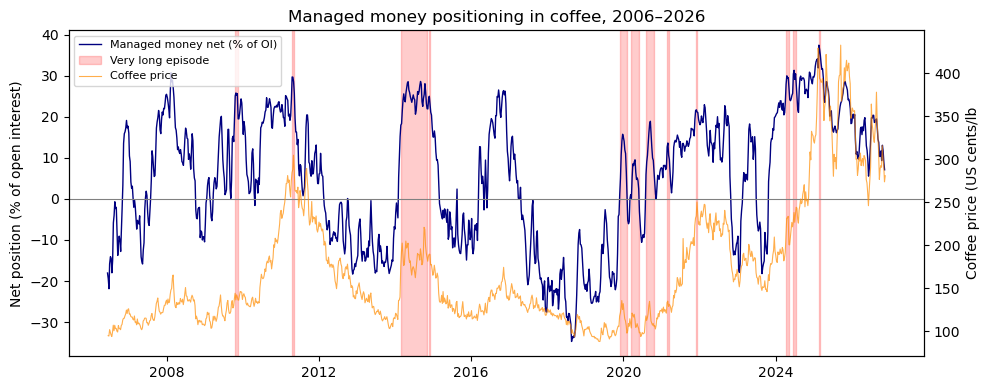

In [30]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(coffee.index, coffee['%_of_oi'], color='navy', linewidth=1, label='Managed money net (% of OI)')
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_ylabel('Net position (% of open interest)')

for i, row in episodes.iterrows():
    ax.axvspan(row['start'], row['end'] + pd.Timedelta(days=7), color='red', alpha=0.2,
               label='Very long episode' if i == 0 else None)

ax2 = ax.twinx()
ax2.plot(weekly.index, weekly, color='darkorange', linewidth=0.8, alpha=0.7, label='Coffee price')
ax2.set_ylabel('Coffee price (US cents/lb')

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)

ax.set_title('Managed money positioning in coffee, 2006–2026')
plt.tight_layout()
plt.savefig('cot_chart1_positioning.png', dpi=300)
plt.show()

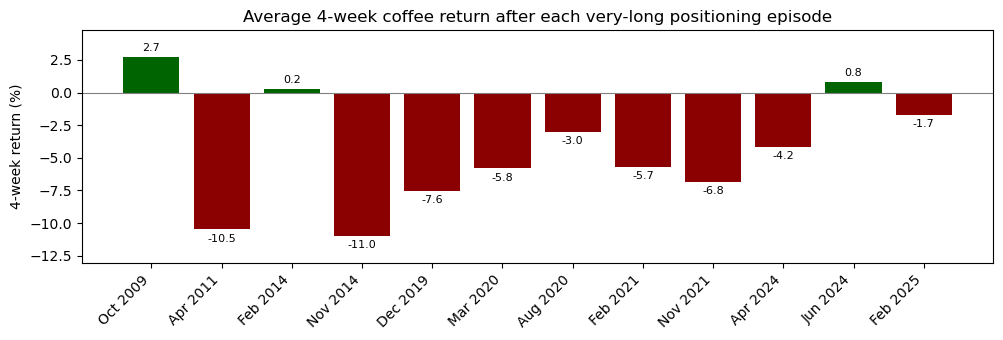

In [27]:
ep = episodes.copy()
ep['mean_4w_pct'] = ep['mean_4w'] * 100
colours = ['darkred' if r < 0 else 'darkgreen' for r in ep['mean_4w_pct']]
labels = ep['start'].dt.strftime('%b %Y')

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(labels, ep['mean_4w_pct'], color=colours)
ax.axhline(0, color='grey', linewidth=0.8)
ax.bar_label(ax.containers[0], fmt='%.1f', padding=3, fontsize=8)
ax.margins(y=0.15)

ax.set_title('Average 4-week coffee return after each very-long positioning episode')
ax.set_ylabel('4-week return (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('cot_chart2_episodes.png', dpi=300)
plt.show()

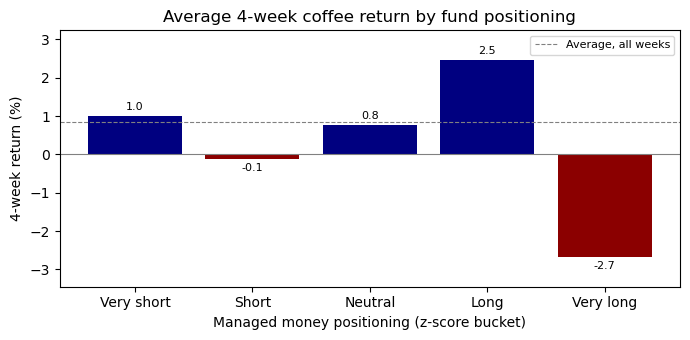

In [28]:
s = summary.copy()
s['mean_4w_pct'] = s['mean_4w'] * 100
colours = ['darkred' if r < 0 else 'navy' for r in s['mean_4w_pct']]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(s.index.astype(str), s['mean_4w_pct'], color=colours)
ax.axhline(0, color='grey', linewidth=0.8)
ax.axhline(coffee['future_rv_4w'].mean() * 100, color='grey', linestyle='--',
           linewidth=0.8, label='Average, all weeks')
ax.bar_label(ax.containers[0], fmt='%.1f', padding=3, fontsize=8)
ax.margins(y=0.15)

ax.set_title('Average 4-week coffee return by fund positioning')
ax.set_xlabel('Managed money positioning (z-score bucket)')
ax.set_ylabel('4-week return (%)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('cot_chart3_buckets.png', dpi=300)
plt.show()